# Entrenamiento de la tesis en Colab (v3: con las fotos de ODK)

1. `tesis_colab.zip` debe estar en tu Drive, en **`MyDrive/tesis`**.
2. *Entorno de ejecución → Cambiar tipo de entorno → GPU A100*.
3. *Entorno de ejecución → Ejecutar todas*.

Corre los 7 entrenamientos del protocolo, **3 a la vez** en la misma GPU, cuantiza cada uno a int8 y lo evalúa. La celda de avance se refresca cada minuto. Cada run terminado queda en `MyDrive/tesis/runs_odk/` (los runs sin ODK quedan en `runs/`). El experimento B usa solo el histórico, que no cambió: sus runs se copian de `runs/` en lugar de reentrenarse. Si Colab se desconecta, *Ejecutar todas* de nuevo: lo terminado se salta y un run ya entrenado retoma desde la cuantización.

Al final, el **experimento de cuantización** compara cuatro formatos para el teléfono sobre los modelos ya entrenados, y el
**análisis según la planificación** mide la verificación contra convenio, la hipótesis 5.8 y los errores por cadena
(ninguno de los dos reentrena). Todas las métricas se calculan sobre la prueba sin duplicados y, en el experimento A,
con las 16 capturas inválidas de campo aprobadas después de entrenar. **Requiere el `tesis_colab.zip` nuevo** (el
que trae esas fotos aprobadas): si el de Drive es anterior, súbelo de nuevo.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/tesis'
RUNS_DIR = f'{DRIVE}/runs_odk'  # v3: con las fotos de ODK; los runs anteriores quedan en runs/
!mkdir -p "{RUNS_DIR}"
import glob, os, shutil
for r in glob.glob(f'{DRIVE}/runs/B_*'):  # el experimento B usa solo el histórico: no cambia con ODK
    if not os.path.exists(f'{RUNS_DIR}/{os.path.basename(r)}'):
        shutil.copytree(r, f'{RUNS_DIR}/{os.path.basename(r)}')
!nvidia-smi -L

Mounted at /content/drive
GPU 0: NVIDIA L4 (UUID: GPU-53bb9138-b0c7-ec39-000e-8837bdf071cd)


In [2]:
# Copia al disco local de Colab: leer 58 000 fotos desde Drive en cada época sería lentísimo.
%cd /content
!cp "{DRIVE}/tesis_colab.zip" /content/ && unzip -q -o tesis_colab.zip -d /content/tesis && rm tesis_colab.zip
%cd /content/tesis

/content
/content/tesis


Código actualizado respecto del zip: fotos decodificadas en RAM tras la primera época y aumentos en la GPU (mismo protocolo, más rápido), y las métricas del análisis (el bootstrap sobre un subconjunto de clases y el convenio aproximado de cada local, `metrics.contracts`). Van antes de cualquier `import tesis...`: Python guarda el módulo importado y no vería la versión nueva.

In [3]:
%%writefile tesis/data.py
"""Carga de imágenes con tf.data. El enmascaramiento de la superposición vive dentro del modelo
(ver train.build_model), así la versión TFLite lo aplica igual en el dispositivo."""
import keras
import tensorflow as tf

from .config import CLASSES, IMG_SIZE, SEED

AUGMENT = keras.Sequential([
    keras.layers.RandomRotation(0.03, fill_mode="constant"),
    keras.layers.RandomZoom((-0.15, 0.0)),  # recorte aleatorio
    keras.layers.RandomTranslation(0.05, 0.05, fill_mode="constant"),
    keras.layers.RandomBrightness(0.25, value_range=(0, 255)),
    keras.layers.RandomContrast(0.25),
])
# ponytail: sin capa de perspectiva nativa en Keras; RandomZoom+Translation la aproximan.


def _load(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8), label  # uint8: 4x menos RAM en caché


def _jpeg(img, label):
    img = tf.image.random_jpeg_quality(img, 40, 95)  # compresión con pérdida
    return tf.cast(img, tf.float32), label


def _float(img, label):
    return tf.cast(img, tf.float32), label


def dataset(df, batch=32, train=False):
    """df con columnas path y label (nombre de clase). Imágenes float32 en [0, 255].
    Las fotos se decodifican una vez y quedan en RAM (cache); los aumentos se sortean en cada época."""
    labels = df.label.map(CLASSES.index).values
    ds = tf.data.Dataset.from_tensor_slices((df.path.values, labels))
    ds = ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if train:  # AUGMENT no va aquí sino en train.py, envolviendo al modelo: así corre en la GPU
        ds = ds.shuffle(len(df), seed=SEED).map(_jpeg, num_parallel_calls=tf.data.AUTOTUNE).batch(batch)
    else:
        ds = ds.map(_float, num_parallel_calls=tf.data.AUTOTUNE).batch(batch)
    return ds.prefetch(tf.data.AUTOTUNE)


Overwriting tesis/data.py


In [4]:
%%writefile tesis/train.py
"""Entrenamiento por transferencia con protocolo común (sección 5.5).

Uso:
    python -m tesis.train --model mobilenetv3 --exp A
    python -m tesis.train --model resnet50 --exp A --no-mask   # control del atajo de la superposición
"""
import argparse
import json
from pathlib import Path

import keras
import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight

from .config import CLASSES, IMG_SIZE, MASK_H, MASK_W, MODELS, SEED
from .data import AUGMENT, dataset
from .split import experiment


def overlay_mask():
    m = np.ones((IMG_SIZE, IMG_SIZE, 1), dtype="float32")
    m[-round(IMG_SIZE * MASK_H):, -round(IMG_SIZE * MASK_W):] = 0
    return m


def build_model(name, mask=True):
    """Entrada: RGB float32 [0, 255] de IMG_SIZE². Máscara y preprocesamiento incluidos en el grafo."""
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = inp * overlay_mask() if mask else inp
    shape = (IMG_SIZE, IMG_SIZE, 3)
    if name == "resnet50":
        x = keras.applications.resnet50.preprocess_input(x)
        base = keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=shape, pooling="avg")
    elif name == "mobilenetv3":
        base = keras.applications.MobileNetV3Large(include_top=False, weights="imagenet", input_shape=shape, pooling="avg")
    elif name == "efficientnetb0":
        base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=shape, pooling="avg")
    else:
        raise ValueError(f"modelo desconocido: {name}")
    x = keras.layers.Dropout(0.2)(base(x))
    return keras.Model(inp, keras.layers.Dense(len(CLASSES), activation="softmax")(x), name=name)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", choices=MODELS, required=True)
    ap.add_argument("--exp", choices=["A", "B"], default="A")
    ap.add_argument("--no-mask", action="store_true")
    ap.add_argument("--manifest", default="data/manifest.csv")
    ap.add_argument("--stores", default="data/stores_split.csv")
    ap.add_argument("--epochs", type=int, default=40)
    ap.add_argument("--lr", type=float, default=1e-4)
    ap.add_argument("--batch", type=int, default=32)
    args = ap.parse_args()

    keras.utils.set_random_seed(SEED)
    df = pd.read_csv(args.manifest)
    parts = experiment(df[df.label.notna()], pd.read_csv(args.stores), args.exp)
    run = Path("runs") / f"{args.exp}_{args.model}{'_nomask' if args.no_mask else ''}"
    run.mkdir(parents=True, exist_ok=True)

    y = parts["train"].label.map(CLASSES.index).values
    present = np.unique(y)
    weights = dict(zip(present.tolist(), compute_class_weight("balanced", classes=present, y=y)))

    model = build_model(args.model, mask=not args.no_mask)
    # Los aumentos envuelven al modelo solo para entrenar (corren en la GPU); se guarda `model`, sin ellos.
    trainer = keras.Sequential([keras.Input((IMG_SIZE, IMG_SIZE, 3)), AUGMENT, model])
    trainer.compile(keras.optimizers.Adam(args.lr), "sparse_categorical_crossentropy", metrics=["accuracy"])
    trainer.fit(
        dataset(parts["train"], args.batch, train=True),
        validation_data=dataset(parts["val"], args.batch),
        epochs=args.epochs,
        class_weight=weights,
        callbacks=[
            keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(patience=3, factor=0.3),
            keras.callbacks.CSVLogger(run / "history.csv"),
        ],
    )
    model.save(run / "model.keras")
    for k, v in parts.items():
        v.to_csv(run / f"{k}.csv", index=False)
    json.dump(vars(args), open(run / "args.json", "w"), indent=2)
    print(f"guardado en {run}")


if __name__ == "__main__":
    main()


Overwriting tesis/train.py


In [5]:
%%writefile tesis/evaluate.py
"""Evalúa un run sobre su conjunto de prueba (Keras o TFLite) y escribe métricas en JSON.

Uso:
    python -m tesis.evaluate runs/A_mobilenetv3 model_int8.tflite --contracts data/contracts.csv
contracts.csv (opcional): store, label   -> una fila por convenio vigente del local.
"""
import argparse
import json
from pathlib import Path

import keras
import numpy as np
import pandas as pd
import tensorflow as tf

from .config import CLASSES
from .data import dataset
from .metrics import report, verification


def predict(model_path, df):
    ds = dataset(df, batch=1 if model_path.suffix == ".tflite" else 64)
    if model_path.suffix != ".tflite":
        return keras.models.load_model(model_path).predict(ds)
    try:
        it = tf.lite.Interpreter(str(model_path))
        it.allocate_tensors()
    except RuntimeError:  # XNNPACK no prepara el MobileNetV3 int8: kernels estándar, mismos resultados
        it = tf.lite.Interpreter(str(model_path), experimental_op_resolver_type=(
            tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES))
        it.allocate_tensors()
    inp, out = it.get_input_details()[0]["index"], it.get_output_details()[0]["index"]
    probs = []
    for x, _ in ds:
        it.set_tensor(inp, x.numpy())
        it.invoke()
        probs.append(it.get_tensor(out)[0])
    return np.array(probs)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("run")
    ap.add_argument("model", nargs="?", default="model.keras")
    ap.add_argument("--contracts")
    args = ap.parse_args()

    run = Path(args.run)
    test = pd.read_csv(run / "test.csv")
    probs = predict(run / args.model, test)
    y, stores = test.label.map(CLASSES.index).values, test.store.values

    contracts = None
    if args.contracts:
        contracts = pd.read_csv(args.contracts).groupby("store").label.agg(set).to_dict()
    m = report(y, probs, stores, contracts)
    if contracts:
        m.update(verification(probs, y, stores, contracts))
    m["size_mb"] = (run / args.model).stat().st_size / 2**20

    stem = Path(args.model).stem
    np.save(run / f"probs_{stem}.npy", probs)  # para bootstrap entre configuraciones
    json.dump(m, open(run / f"metrics_{stem}.json", "w"), indent=2, default=float)
    print(json.dumps({k: m[k] for k in ("f1_macro", "recall_macro", "reject_recall", "size_mb")}, indent=2, default=float))


if __name__ == "__main__":
    main()


Overwriting tesis/evaluate.py


In [6]:
%%writefile tesis/metrics.py
"""Métricas predictivas, verificación contra convenio y viabilidad (secciones 5.6–5.9).

`probs`: matriz (n, 7) en el orden de config.CLASSES. `y`: índices de clase verdadera.
`contracts`: dict store -> set de nombres de clase con convenio vigente.
"""
import numpy as np
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support, recall_score

from .config import CLASSES, REJECT, THRESHOLDS

IDX = {c: i for i, c in enumerate(CLASSES)}
REJECT_IDX = [IDX[c] for c in REJECT]
MUEBLES = [c for c in CLASSES if c not in REJECT]


def contracts(manifest):
    """Muebles con convenio por local, a falta de la maestra de convenios: los que aparecen en las fotos verificadas
    del local y los que ODK declara para él (el formulario solo despliega los contratados). Es un superconjunto del
    convenio: restringe la predicción menos que la maestra, no más."""
    out = {}
    for s, label, declared in manifest[manifest.verified == 1][["store", "label", "declarado"]].itertuples(index=False):
        for c in {label, declared} & set(MUEBLES):
            out.setdefault(s, set()).add(c)
    return out


def conditional_pred(probs, stores, contracts):
    """Argmax restringido a los muebles del local más las dos categorías de rechazo."""
    mask = np.zeros_like(probs, dtype=bool)
    for i, s in enumerate(stores):
        mask[i, [IDX[c] for c in contracts.get(s, CLASSES)] + REJECT_IDX] = True
    return np.where(mask, probs, -np.inf).argmax(1)


def report(y, probs, stores=None, contracts=None):
    pred = probs.argmax(1)
    labels = list(range(len(CLASSES)))
    p, r, _, n = precision_recall_fscore_support(y, pred, labels=labels, zero_division=0)
    out = {
        "f1_macro": f1_score(y, pred, labels=labels, average="macro", zero_division=0),
        "recall_macro": recall_score(y, pred, labels=labels, average="macro", zero_division=0),
        "per_class": {c: {"precision": p[i], "recall": r[i], "support": int(n[i])} for i, c in enumerate(CLASSES)},
        "reject_recall": min(r[i] for i in REJECT_IDX),
        "confusion": confusion_matrix(y, pred, labels=labels, normalize="true").round(3).tolist(),
    }
    if contracts is not None:
        out["conditional_accuracy"] = float((conditional_pred(probs, stores, contracts) == y).mean())
    return out


def bootstrap_f1_diff(y, pred_a, pred_b, stores, n=2000, seed=0, labels=None):
    """IC 95 % de F1-macro(a) - F1-macro(b) con remuestreo por local. `labels`: clases que promedia (todas)."""
    rng = np.random.default_rng(seed)
    stores = np.asarray(stores)
    groups = [np.flatnonzero(stores == s) for s in np.unique(stores)]
    labels = list(range(len(CLASSES))) if labels is None else labels
    diffs = []
    for _ in range(n):
        idx = np.concatenate([groups[i] for i in rng.integers(len(groups), size=len(groups))])
        diffs.append(f1_score(y[idx], pred_a[idx], labels=labels, average="macro", zero_division=0)
                     - f1_score(y[idx], pred_b[idx], labels=labels, average="macro", zero_division=0))
    return tuple(np.percentile(diffs, [2.5, 97.5]))


def verification_pairs(y, stores, contracts):
    """Pares (imagen, mueble declarado) por intercambio dentro del local (sección 5.9).

    Solo locales con 2+ convenios e imágenes de mueble con convenio en ese local.
    Devuelve listas paralelas: índice de imagen, índice declarado, es_correcto.
    """
    img, declared, correct = [], [], []
    for i, (label, s) in enumerate(zip(y, stores)):
        own = contracts.get(s, set())
        if len(own) < 2 or CLASSES[label] not in own:
            continue
        for c in own:
            img.append(i)
            declared.append(IDX[c])
            correct.append(IDX[c] == label)
    return np.array(img), np.array(declared), np.array(correct)


def verification(probs, y, stores, contracts):
    """Tasa de detección sobre pares discrepantes y de falsas alarmas sobre pares correctos."""
    img, declared, correct = verification_pairs(y, stores, contracts)
    pred = conditional_pred(probs, stores, contracts)[img]
    alert = pred != declared  # cualquier alerta: discrepancia o rechazo
    return {"detection_rate": float(alert[~correct].mean()), "false_alarm": float(alert[correct].mean()),
            "n_mismatch": int((~correct).sum()), "n_correct": int(correct.sum())}


def failed_criteria(m):
    """Criterios de la tabla 5.7 que `m` incumple. Lista vacía = configuración viable.
    `m` puede traer: f1_macro, recall_macro, reject_recall, false_alarm, quant_drop,
    lat_p50_ms, lat_p95_ms, mem_mb, size_mb. Las claves ausentes se reportan como pendientes."""
    higher = {"f1_macro", "recall_macro", "reject_recall"}
    return [k for k, t in THRESHOLDS.items()
            if k not in m or (m[k] < t if k in higher else m[k] > t)]

Overwriting tesis/metrics.py


In [7]:
import os, subprocess, time
from pathlib import Path
import pandas as pd
from IPython.display import clear_output

os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'  # cada proceso toma solo la memoria de GPU que usa
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
PARALLEL = 3
RUNS = [  # (modelo, experimento, sin máscara); los más lentos primero
    ('resnet50', 'A', False), ('resnet50', 'B', False),
    ('efficientnetb0', 'A', False), ('efficientnetb0', 'B', False),
    ('mobilenetv3', 'A', False), ('mobilenetv3', 'B', False),
    ('mobilenetv3', 'A', True),  # control del atajo de la superposición
]

def name_of(model, exp, nomask):
    return f"{exp}_{model}{'_nomask' if nomask else ''}"

def command(model, exp, nomask):
    name, saved = name_of(model, exp, nomask), f'{RUNS_DIR}/' + name_of(model, exp, nomask)
    if os.path.exists(f'{saved}/model.keras'):  # entrenado antes de una desconexión: se retoma
        steps = [f'mkdir -p runs && cp -r "{saved}" runs/']
    else:
        steps = [f'python -m tesis.train --model {model} --exp {exp}' + (' --no-mask' if nomask else ''),
                 f'cp -r runs/{name} "{RUNS_DIR}/"']
    steps += [f'python -m tesis.quantize runs/{name}',
              f'python -m tesis.evaluate runs/{name} model.keras',
              f'python -m tesis.evaluate runs/{name} model_int8.tflite',
              f'cp -r runs/{name} "{RUNS_DIR}/"']
    return ' && '.join(steps)

def status(name):
    h = Path(f'runs/{name}/history.csv')
    if Path(f'runs/{name}/model_int8.tflite').exists():
        return f'{name}: entrenado; evaluando'
    if not h.exists() or h.stat().st_size < 60:
        return f'{name}: época 1 en curso'
    d = pd.read_csv(h)
    return (f'{name}: {len(d)} épocas · val_accuracy última {d.val_accuracy.iloc[-1]:.3f}, '
            f'mejor {d.val_accuracy[d.val_loss.idxmin()]:.3f} · {len(d) - 1 - d.val_loss.idxmin()} sin mejorar')

Path('logs').mkdir(exist_ok=True)
pending = [r for r in RUNS if not os.path.exists(f'{RUNS_DIR}/{name_of(*r)}/metrics_model_int8.json')]
running, finished, t0 = {}, [], time.time()
while pending or running:
    while pending and len(running) < PARALLEL:
        r = pending.pop(0)
        running[name_of(*r)] = subprocess.Popen(command(*r), shell=True, stderr=subprocess.STDOUT,
                                                stdout=open(f'logs/{name_of(*r)}.log', 'w'))
    for name, p in list(running.items()):
        if p.poll() is not None:
            finished.append(f"{name}: {'listo, guardado en Drive' if p.returncode == 0 else 'FALLÓ, ver logs/' + name + '.log'}")
            del running[name]
    clear_output(wait=True)
    print(f'{(time.time() - t0) / 3600:.1f} h · en curso {len(running)} · en cola {len(pending)} · terminados {len(finished)}')
    for name in running:
        print('  ', status(name))
    for line in finished:
        print('  ', line)
    if running:
        time.sleep(60)
for line in finished:
    if 'FALLÓ' in line:
        name = line.split(':')[0]
        print(f'--- {name} (últimas líneas) ---'); print(''.join(open(f'logs/{name}.log').readlines()[-25:]))

## Prueba: sin duplicados y con las capturas inválidas aprobadas (secciones 5.3 y 5.4)

92 fotos de la prueba están también, idénticas, en otro local: la misma foto archivada en dos carpetas de local (TIA 133
y TIA 546 comparten 16), copiada con otro nombre (`… (1).jpg`) o adjuntada de nuevo desde la galería en otra sumisión
de ODK. 88 tienen la copia en un local de entrenamiento o validación, así que son fuga: la deduplicación solo comparaba
fotos dentro de cada local. Desde aquí todas las métricas las excluyen. `tesis.build_dataset` ya las descarta al
reconstruir el conjunto y conserva la copia que no es de prueba, así que el entrenamiento no cambia.

La prueba del experimento A tenía dos capturas inválidas reales, así que el recall de esa clase solo podía valer 0,
0.5 o 1. Las 16 fotos oscuras de ODK de los locales de prueba (lente tapado, bolsillo, foto negra) se revisaron a mano
y se aprobaron como capturas inválidas: ahora son 18. Los runs se entrenaron antes y no las tienen en su `test.csv`,
así que `cargar` las predice con cada formato (la primera vez, unos minutos) y las suma. La prueba B usa solo el
histórico y no cambia.

In [8]:
# Las 92 fotos, calculadas con tesis.split.cross_store_duplicates sobre data/hashes.csv (no viaja en el zip).
import glob, json
import numpy as np
from tesis.evaluate import predict

DUPLICADOS = {
    '00ce0c8c_TimePhoto_20251117_120856.jpg', '042495e5_TimePhoto_20240715_110010.jpg',
    '053d60c6_TimePhoto_20250805_105145.jpg', '09293606_TimePhoto_20251117_121235.jpg',
    '09b0d69e_TimePhoto_20251117_121203.jpg', '0e25f7c3_TimePhoto_20251117_114833.jpg',
    '0ebc04a1_CC80306E-ACE3-4F70-A378-097ED2C5C398.jpg', '19e47d87_TimePhoto_20250814_150530.jpg',
    '1b703e65_TimePhoto_20250616_115535.jpg', '2182e8ad_TimePhoto_20250114_130137.jpg',
    '21ed02f9_c5ae4682-1a27-40ff-b751-5c3dd18e2b87.jpg', '22164c08_TimePhoto_20251117_121306.jpg',
    '24d0bad2_TimePhoto_20240312_103124.jpg', '287b1569_TimePhoto_20250915_104246.jpg',
    '2a3c992c_TimePhoto_20251226_110537.jpg', '2d8ebfb5_TimePhoto_20240104_085053.jpg',
    '2d9e63a8_TimePhoto_20251111_144047.jpg', '2ddbfbd1_TimePhoto_20250814_150445.jpg',
    '2ea57afe_TimePhoto_20250814_145445.jpg', '3102981c_TimePhoto_20250915_104201.jpg',
    '32ef2139_TimePhoto_20250114_130209.jpg', '3372533f_TimePhoto_20250814_152044.jpg',
    '35d809e6_TimePhoto_20250114_142335.jpg', '391bf01e_1791470143949.jpg',
    '3a0abc80_TimePhoto_20250916_160526.jpg', '3aa2bf64_c606af50-f922-41f3-a7fc-a20623c3f154.jpg',
    '3d82205e_TimePhoto_20240401_100047.jpg', '3f4fb107_TimePhoto_20250114_135108.jpg',
    '407511a6_TimePhoto_20251226_110740.jpg', '49f412f4_TC_00518.jpg', '4f4d1250_TimePhoto_20250702_161655.jpg',
    '4f5336a9_TimePhoto_20240214_131808.jpg', '53a15120_TimePhoto_20250805_105142.jpg',
    '53f3a053_TimePhoto_20240111_115057.jpg', '56c5b240_TimePhoto_20251117_120931.jpg',
    '5cde8764_TimePhoto_20240104_085254.jpg', '5e5311f8_TimePhoto_20250814_150954.jpg',
    '5f4b14c5_TimePhoto_20250114_141402.jpg', '689300c1_TimePhoto_20240618_143237.jpg',
    '68f58dd0_TimePhoto_20251111_144040.jpg', '69861d2f_TimePhoto_20241017_095414.jpg',
    '6a7b22f7_TimePhoto_20240104_085040.jpg', '6ee16264_TimePhoto_20250711_104343.jpg',
    '71f7e5a9_TimePhoto_20241008_085300.jpg', '72e28a0e_1792099512383.jpg', '74a533a7_TC_00516.jpg',
    '74fd697a_TimePhoto_20250915_104043.jpg', '7708c82d_TimePhoto_20250805_105151.jpg',
    '7b7bf131_TimePhoto_20251117_121254.jpg', '7b85fadc_TimePhoto_20240807_092345.jpg',
    '7cb18f20_TimePhoto_20240715_110110.jpg', '7d64376c_TimePhoto_20240715_105931.jpg',
    '7d70a33c_TimePhoto_20240105_150757.jpg', '7f3ff1e5_TimePhoto_20250120_123704.jpg',
    '8011fe99_TimePhoto_20251111_144036.jpg', '823d7ca6_TimePhoto_20241217_170124.jpg',
    '85ee64d4_TimePhoto_20240403_164903.jpg', '86c4b714_TimePhoto_20240401_094633.jpg',
    '87300a23_TimePhoto_20250114_140616.jpg', '88d8b406_TimePhoto_20250814_150317.jpg',
    '894e66a5_TimePhoto_20250915_104717.jpg', '8cce993d_TimePhoto_20240715_110120.jpg',
    '97743061_TimePhoto_20240912_123330.jpg', '98db6055_TimePhoto_20241115_164534.jpg',
    '99f2e897_TimePhoto_20250114_134848.jpg', '9a3af6aa_TimePhoto_20240715_105941.jpg',
    '9bfa6b19_TimePhoto_20250805_105208.jpg', 'a77d5195_TimePhoto_20250814_150354.jpg',
    'ab2eeb7d_TimePhoto_20240410_095946.jpg', 'acffffda_TimePhoto_20250822_112221.jpg',
    'aeaf3d14_TimePhoto_20240312_103048.jpg', 'af091914_TimePhoto_20251111_144033.jpg',
    'b5ed6345_20256997-a773-4f4b-94d0-d0178775c989.jpg', 'b604e5ca_TimePhoto_20240618_143137.jpg',
    'b63839ff_TimePhoto_20251111_144057.jpg', 'bc8eabdc_TimePhoto_20251226_110712.jpg',
    'c438f6c7_TimePhoto_20240618_143247.jpg', 'c4c6e284_TimePhoto_20250805_105148.jpg',
    'c738a863_TimePhoto_20250114_134709.jpg', 'cd29fcca_576ed733-537d-413a-a0f9-565a49b5a50c.jpg',
    'd207e800_TimePhoto_20251117_121113.jpg', 'd502421b_TimePhoto_20250320_162504.jpg',
    'd7b61a44_TimePhoto_20240715_110024.jpg', 'e131ec1a_TimePhoto_20251111_144050.jpg',
    'e3c1b324_TimePhoto_20251226_110637.jpg', 'e4eaee0c_TimePhoto_20251111_144100.jpg',
    'e7753744_TimePhoto_20250114_135235.jpg', 'e833e7ac_TimePhoto_20240618_143201.jpg',
    'f50c2b53_TimePhoto_20250114_134604.jpg', 'f817aa8e_8a250c1c-ca52-4740-ae9b-790e9ed08495.jpg',
    'ff0dd314_TimePhoto_20250814_152039.jpg', 'ff2dab3b_TimePhoto_20240401_094048.jpg'
}

# Las capturas inválidas verificadas de los locales de prueba: la que ya estaba en la prueba y las 16 aprobadas después.
manifest = pd.read_csv('data/manifest.csv')
locales = pd.read_csv('data/stores_split.csv')
APROBADAS = manifest[(manifest.source == 'odk') & (manifest.verified == 1) & (manifest.label == 'captura_invalida')
                     & manifest.store.isin(locales.store[locales.split == 'test'])]
assert len(APROBADAS) > 1, 'El zip de Drive es anterior: sube el tesis_colab.zip nuevo a MyDrive/tesis'
_extra = {}

def cargar(run, fmt='model'):
    """Prueba del run sin los duplicados, más las capturas aprobadas en el experimento A, y las probabilidades del
    formato, alineadas. Las aprobadas se predicen una vez por run y formato."""
    test = pd.read_csv(f'{RUNS_DIR}/{run}/test.csv')
    keep = ~test.path.str.rsplit('/', n=1).str[-1].isin(DUPLICADOS).values
    test, P = test[keep], np.load(f'{RUNS_DIR}/{run}/probs_{fmt}.npy')[keep]
    if run.startswith('A_'):
        extra = APROBADAS[~APROBADAS.path.isin(test.path)]
        if (run, fmt) not in _extra:
            _extra[run, fmt] = predict(Path(RUNS_DIR) / run / ('model.keras' if fmt == 'model' else f'{fmt}.tflite'), extra)
        test, P = pd.concat([test, extra.reindex(columns=test.columns)]), np.r_[P, _extra[run, fmt]]
    return test.reset_index(drop=True), P

for f in sorted(glob.glob(f'{RUNS_DIR}/*/test.csv')):
    t, run = pd.read_csv(f), f.split('/')[-2]
    extra = (~APROBADAS.path.isin(t.path)).sum() if run.startswith('A_') else 0
    print(f'{run}: {t.path.str.rsplit("/", n=1).str[-1].isin(DUPLICADOS).sum()} de {len(t):,} fotos de prueba fuera, '
          f'{extra} capturas inválidas aprobadas dentro')


A_efficientnetb0: 92 de 12,324 fotos de prueba fuera, 16 capturas inválidas aprobadas dentro
A_mobilenetv3: 92 de 12,324 fotos de prueba fuera, 16 capturas inválidas aprobadas dentro
A_mobilenetv3_nomask: 92 de 12,324 fotos de prueba fuera, 16 capturas inválidas aprobadas dentro
A_resnet50: 92 de 12,324 fotos de prueba fuera, 16 capturas inválidas aprobadas dentro
B_efficientnetb0: 19 de 1,316 fotos de prueba fuera, 0 capturas inválidas aprobadas dentro
B_mobilenetv3: 19 de 1,316 fotos de prueba fuera, 0 capturas inválidas aprobadas dentro
B_resnet50: 19 de 1,316 fotos de prueba fuera, 0 capturas inválidas aprobadas dentro


In [9]:
# Resumen sobre la prueba sin duplicados y con las capturas aprobadas (predecirlas tarda unos minutos la primera vez).
# f1_presentes promedia solo las clases con ejemplos en prueba: la B no tiene capturas inválidas reales, y ese recall
# arrastra su f1_macro y su reject_recall.
from sklearn.metrics import f1_score
from tesis.config import CLASSES
from tesis.metrics import report

rows = []
for f in sorted(glob.glob(f'{RUNS_DIR}/*/probs_*.npy')):
    run, fmt = f.split('/')[-2], f.split('probs_')[-1][:-4]
    test, P = cargar(run, fmt)
    y = test.label.map(CLASSES.index).values
    m = report(y, P)
    rows.append({'run': run, 'formato': fmt, 'f1_macro': m['f1_macro'],
                 'f1_presentes': f1_score(y, P.argmax(1), labels=np.unique(y), average='macro'),
                 'recall_macro': m['recall_macro'], 'reject_recall': m['reject_recall'],
                 'size_mb': json.load(open(f'{RUNS_DIR}/{run}/metrics_{fmt}.json'))['size_mb']})
pd.DataFrame(rows).round(3)

1/1 ━━━━━━━━━━━━━━━━━━━━ 18s 18s/step


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use 

1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use 

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use 

,run,formato,f1_macro,f1_presentes,recall_macro,reject_recall,size_mb
0,A_efficientnetb0,model,0.951,0.951,0.948,0.833,16.620
1,A_efficientnetb0,model_dyn,0.951,0.951,0.949,0.833,4.559
2,A_efficientnetb0,model_fp16,0.951,0.951,0.948,0.833,7.865
3,A_efficientnetb0,model_int8,0.792,0.792,0.812,0.222,4.761
4,A_efficientnetb0,model_int8bal,0.805,0.805,0.821,0.389,4.761
5,A_mobilenetv3,model,0.955,0.955,0.951,0.889,12.444
6,A_mobilenetv3,model_dyn,0.952,0.952,0.952,0.889,3.348
7,A_mobilenetv3,model_fp16,0.954,0.954,0.951,0.889,5.866
8,A_mobilenetv3,model_int8,0.574,0.574,0.565,0.222,3.404
9,A_mobilenetv3,model_int8bal,0.612,0.612,0.625,0.000,3.404


## Experimento de cuantización: qué formato conserva la exactitud en el teléfono

La cuantización int8 completa, la estándar de TFLite, rompe las redes móviles ajustadas: en el experimento A,
EfficientNet-B0 pierde 8 puntos de F1-macro y MobileNetV3 30, mientras ResNet-50 no pierde nada pero pesa 23 MB. El
criterio de la tabla 5.7 es perder a lo sumo 2 puntos y pesar a lo sumo 20 MB. Aquí se comparan cuatro formatos
post-entrenamiento sobre los mismos modelos ya entrenados, sin reentrenar:

| Formato | Pesos | Activaciones | Calibración | Tamaño frente a float |
|---|---|---|---|---|
| `model_fp16` | float16 | float | no necesita | ½ |
| `model_dyn` | int8 | float (rango dinámico) | no necesita | ¼ |
| `model_int8` | int8 | int8 | 300 fotos de entrenamiento al azar | ¼ |
| `model_int8bal` | int8 | int8 | 100 fotos por clase | ¼ |

- **Hipótesis.** El daño está en las activaciones, no en los pesos: si es así, fp16 y dyn conservan la exactitud.
  int8bal prueba si la causa es la calibración: al azar, casi la mitad de las fotos son check outs y las clases
  chicas aportan pocas, así que sus activaciones pueden quedar fuera del rango calibrado.
- **Modelos.** Las tres arquitecturas del protocolo en los experimentos A y B: MobileNetV3 y EfficientNet-B0,
  candidatas al teléfono, y ResNet-50, la referencia, que no cabe en 20 MB en ningún formato (en int8 pesa 23 MB). El
  control sin máscara no se despliega.
- **Métrica (sección 5.7).** **Caída** = F1-macro de las 7 clases del modelo float32 − F1-macro del formato, en
  puntos, con IC 95 % por bootstrap pareado que remuestrea locales (2 000 réplicas). Como complemento, la caída sobre
  las clases con al menos 10 fotos en prueba: la prueba B no tiene capturas inválidas reales,
  y la A tiene 18 frente a miles de fotos de las clases grandes. **Acuerdo** = fracción de fotos en que el formato
  predice lo mismo que el modelo float.
- **Criterios.** Los de la tabla 5.7 que se pueden medir aquí: F1-macro ≥ 0.85, recall-macro ≥ 0.90, recall de cada
  categoría de rechazo ≥ 0.90, caída ≤ 2 puntos y tamaño ≤ 20 MB. Latencia y memoria se miden en el Honor X6b; las falsas
  alarmas, en la verificación de la sección 5.9 (análisis del final).

TFLite evalúa en la CPU, foto por foto: es la parte lenta. Si Colab se desconecta, *Ejecutar todas* de nuevo: lo
terminado se salta.

Código nuevo respecto del zip: los formatos de cuantización.

In [10]:
%%writefile tesis/quantize.py
"""Conversión a TFLite post-entrenamiento (sección 5.5, procedimiento estándar de TFLite).

Uso:
    python -m tesis.quantize runs/A_mobilenetv3              # model_fp32 y model_int8
    python -m tesis.quantize runs/A_mobilenetv3 --variantes  # model_fp16, model_dyn y model_int8bal
Formatos, de menos a más agresivo:
    fp32     sin cuantizar.
    fp16     pesos en float16; el teléfono calcula en float.
    dyn      pesos en int8, activaciones en float (rango dinámico): no necesita calibración.
    int8     pesos y activaciones en int8, calibrado con 300 imágenes de entrenamiento al azar.
    int8bal  igual, calibrado con 100 imágenes por clase: al azar, casi la mitad son check outs.
La calibración usa imágenes de entrenamiento sin aumentos.
"""
import sys
from pathlib import Path

import keras
import pandas as pd
import tensorflow as tf

from .data import dataset

N_CALIB = 300
N_CALIB_CLASE = 100


def saved_model(run):
    saved = run / "saved_model"
    keras.models.load_model(run / "model.keras").export(saved)
    return str(saved)


def converter(saved, optimize=True):
    conv = tf.lite.TFLiteConverter.from_saved_model(saved)
    if optimize:
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
    return conv


def int8(saved, calib):
    def representative():
        for x, _ in dataset(calib, batch=1):
            yield [x]

    conv = converter(saved)
    conv.representative_dataset = representative
    conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    # Entrada y salida quedan en float32: la app entrega RGB [0, 255] sin conocer la escala int8.
    return conv.convert()


def fp16(saved):
    conv = converter(saved)
    conv.target_spec.supported_types = [tf.float16]
    return conv.convert()


def convert(run, variantes=False):
    run = Path(run)
    saved = saved_model(run)
    train = pd.read_csv(run / "train.csv")
    if variantes:
        out = {"model_fp16": fp16(saved),
               "model_dyn": converter(saved).convert(),  # sin representative_dataset: rango dinámico
               "model_int8bal": int8(saved, train.sample(frac=1, random_state=0).groupby("label").head(N_CALIB_CLASE))}
    else:
        out = {"model_fp32": converter(saved, optimize=False).convert(),
               "model_int8": int8(saved, train.sample(N_CALIB, random_state=0))}
    for name, model in out.items():
        (run / f"{name}.tflite").write_bytes(model)
        print(f"{name}.tflite", f"{len(model) / 2**20:.1f} MB")


if __name__ == "__main__":
    convert(sys.argv[1], "--variantes" in sys.argv)

Overwriting tesis/quantize.py


In [11]:
# Cuantización: 3 formatos nuevos por run, los 6 runs en paralelo (TFLite evalúa en la CPU).
RUNS_CUANT = ['A_resnet50', 'B_resnet50', 'A_efficientnetb0', 'B_efficientnetb0', 'A_mobilenetv3', 'B_mobilenetv3']
FORMATOS = ['model.keras', 'model_int8.tflite', 'model_fp16.tflite', 'model_dyn.tflite', 'model_int8bal.tflite']

def falta(name, f):
    return not os.path.exists(f'{RUNS_DIR}/{name}/probs_{Path(f).stem}.npy')

def command_q(name):
    steps = [f'mkdir -p runs && cp -r "{RUNS_DIR}/{name}" runs/']
    if any(falta(name, f) for f in FORMATOS[2:]):
        steps.append(f'python -m tesis.quantize runs/{name} --variantes')
    steps += [f'python -m tesis.evaluate runs/{name} {f}' for f in FORMATOS if falta(name, f)]
    return ' && '.join(steps + [f'cp -r runs/{name} "{RUNS_DIR}/"'])

Path('logs').mkdir(exist_ok=True)
procs = {n: subprocess.Popen(command_q(n), shell=True, stderr=subprocess.STDOUT, stdout=open(f'logs/q_{n}.log', 'w'))
         for n in RUNS_CUANT if any(falta(n, f) for f in FORMATOS)}
t0 = time.time()
while any(p.poll() is None for p in procs.values()):
    clear_output(wait=True)
    print(f'{(time.time() - t0) / 60:.0f} min')
    for n, p in procs.items():
        hechos = len(list(Path(f'runs/{n}').glob('probs_*.npy')))
        print(f'   {n}: {hechos}/{len(FORMATOS)} formatos evaluados' + ('' if p.poll() is None else ' · terminado'))
    time.sleep(60)
for n, p in procs.items():
    print(n, 'listo, guardado en Drive' if p.returncode == 0 else
          'FALLÓ, últimas líneas:\n' + ''.join(open(f'logs/q_{n}.log').readlines()[-25:]))
if not procs:
    print('Todos los formatos ya estaban evaluados.')

Todos los formatos ya estaban evaluados.


In [12]:
# Resultados (prueba sin duplicados): F1-macro, caída frente al modelo float32 con IC 95 % (bootstrap por local),
# acuerdo y criterios de la tabla 5.7 que se miden aquí. Tarda unos minutos.
from tesis.config import THRESHOLDS
from tesis.metrics import bootstrap_f1_diff, failed_criteria

TODAS = list(range(len(CLASSES)))
filas, por_clase = [], []
for n in RUNS_CUANT:
    test, _ = cargar(n)
    y = test.label.map(CLASSES.index).values
    clases = [i for i in TODAS if (y == i).sum() >= 10]
    f1 = lambda p, l=TODAS: f1_score(y, p, labels=l, average='macro', zero_division=0)
    probs = {Path(f).stem: cargar(n, Path(f).stem)[1] for f in FORMATOS}
    base = probs['model'].argmax(1)
    for fmt, P in probs.items():
        p = P.argmax(1)
        m = report(y, P) | {'size_mb': json.load(open(f'{RUNS_DIR}/{n}/metrics_{fmt}.json'))['size_mb'],
                            'quant_drop': f1(base) - f1(p)}
        fallas = failed_criteria(m)
        ic = '' if fmt == 'model' else '[{:.3f}, {:.3f}]'.format(*bootstrap_f1_diff(y, base, p, test.store.values))
        filas.append({'run': n, 'formato': fmt, 'MB': m['size_mb'], 'F1-macro': m['f1_macro'],
                      'recall-macro': m['recall_macro'], 'recall rechazo': m['reject_recall'],
                      'caída': m['quant_drop'], 'IC 95 % caída': ic, 'caída (≥10 fotos)': f1(base, clases) - f1(p, clases),
                      'acuerdo': (p == base).mean(), 'incumple': ', '.join(k for k in fallas if k in m)})
        por_clase.append({'run': n, 'formato': fmt, **dict(zip(CLASSES, f1_score(y, p, labels=TODAS, average=None,
                                                                                 zero_division=0)))})
cuant, por_clase = pd.DataFrame(filas), pd.DataFrame(por_clase)
print('Pendientes para todos: latencia y memoria (Honor X6b); las falsas alarmas, en el análisis del final.')
print('F1 por clase (experimento A): dónde pierde cada formato')
display(por_clase[por_clase.run.str.startswith('A')].set_index(['run', 'formato']).round(3))
cuant.round(3)

Pendientes para todos: latencia y memoria (Honor X6b); las falsas alarmas, en el análisis del final.
F1 por clase (experimento A): dónde pierde cada formato


chiclera  lateral  check_out  cabecera  \
run              formato                                                 
A_resnet50       model             0.986    0.898      0.991     0.956   
                 model_int8        0.985    0.895      0.991     0.956   
                 model_fp16        0.986    0.898      0.991     0.956   
                 model_dyn         0.985    0.894      0.991     0.957   
                 model_int8bal     0.985    0.897      0.991     0.955   
A_efficientnetb0 model             0.979    0.944      0.990     0.968   
                 model_int8        0.953    0.808      0.927     0.920   
                 model_fp16        0.979    0.944      0.990     0.968   
                 model_dyn         0.983    0.943      0.990     0.966   
                 model_int8bal     0.954    0.784      0.905     0.915   
A_mobilenetv3    model             0.985    0.934      0.991     0.962   
                 model_int8        0.835    0.389      0.839     0.690   
                 model_fp16        0.985    0.933      0.991     0.962   
                 model_dyn         0.984    0.928      0.990     0.960   
                 model_int8bal     0.735    0.723      0.839     0.773   

                                exhibidor_piso  captura_invalida  \
run              formato                                           
A_resnet50       model                   0.935             0.941   
                 model_int8              0.934             0.941   
                 model_fp16              0.935             0.941   
                 model_dyn               0.933             0.941   
                 model_int8bal           0.932             0.941   
A_efficientnetb0 model                   0.947             0.882   
                 model_int8              0.774             0.364   
                 model_fp16              0.947             0.882   
                 model_dyn               0.949             0.882   
                 model_int8bal           0.712             0.560   
A_mobilenetv3    model                   0.936             0.914   
                 model_int8              0.534             0.364   
                 model_fp16              0.935             0.914   
                 model_dyn               0.935             0.914   
                 model_int8bal           0.512             0.000   

                                contenido_ajeno  
run              formato                         
A_resnet50       model                    0.939  
                 model_int8               0.939  
                 model_fp16               0.939  
                 model_dyn                0.938  
                 model_int8bal            0.939  
A_efficientnetb0 model                    0.947  
                 model_int8               0.800  
                 model_fp16               0.947  
                 model_dyn                0.946  
                 model_int8bal            0.806  
A_mobilenetv3    model                    0.960  
                 model_int8               0.368  
                 model_fp16               0.960  
                 model_dyn                0.956  
                 model_int8bal            0.703

,run,formato,MB,F1-macro,recall-macro,recall rechazo,caída,IC 95 % caída,caída (≥10 fotos),acuerdo,incumple
0,A_resnet50,model,90.996,0.950,0.945,0.889,0.000,,0.000,1.000,"reject_recall, size_mb"
1,A_resnet50,model_int8,23.212,0.949,0.943,0.889,0.001,"[-0.000, 0.002]",0.001,0.998,"reject_recall, size_mb"
2,A_resnet50,model_fp16,45.012,0.950,0.945,0.889,0.000,"[0.000, 0.000]",0.000,1.000,"reject_recall, size_mb"
3,A_resnet50,model_dyn,23.048,0.948,0.943,0.889,0.001,"[0.000, 0.003]",0.001,0.999,"reject_recall, size_mb"
4,A_resnet50,model_int8bal,23.212,0.949,0.943,0.889,0.001,"[-0.000, 0.002]",0.001,0.998,"reject_recall, size_mb"
5,B_resnet50,model,90.996,0.681,0.685,0.000,0.000,,0.000,1.000,"f1_macro, recall_macro, reject_recall, size_mb"
6,B_resnet50,model_int8,23.212,0.679,0.683,0.000,0.002,"[0.000, 0.006]",0.003,0.998,"f1_macro, recall_macro, reject_recall, size_mb"
7,B_resnet50,model_fp16,45.012,0.681,0.685,0.000,0.000,"[0.000, 0.000]",0.000,1.000,"f1_macro, recall_macro, reject_recall, size_mb"
8,B_resnet50,model_dyn,23.048,0.681,0.685,0.000,0.000,"[0.000, 0.000]",0.000,1.000,"f1_macro, recall_macro, reject_recall, size_mb"
9,B_resnet50,model_int8bal,23.212,0.680,0.684,0.000,0.001,"[-0.001, 0.003]",0.001,0.997,"f1_macro, recall_macro, reject_recall, size_mb"


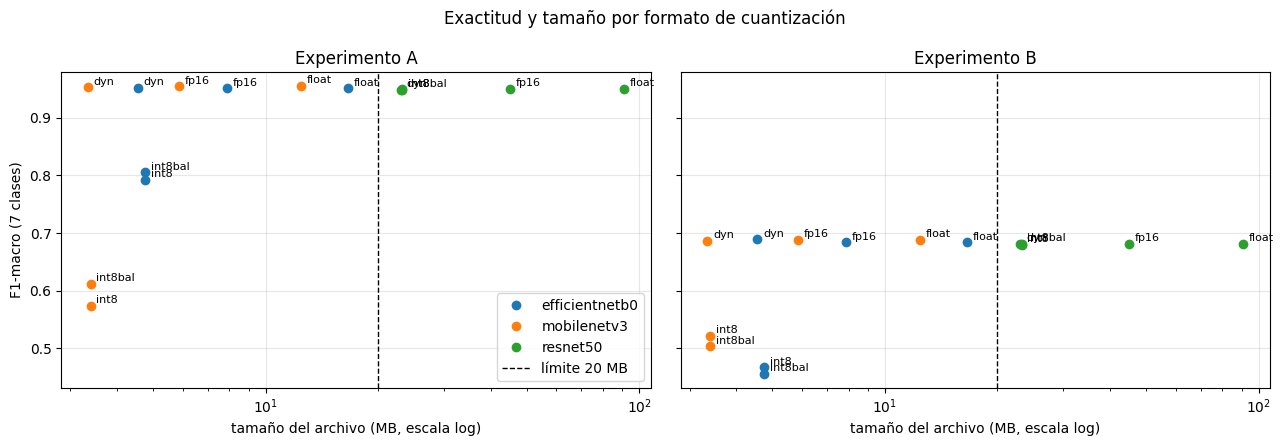

In [13]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for a, exp in zip(axs, 'AB'):
    for n, d in cuant[cuant.run.str.startswith(exp)].groupby('run'):
        a.plot(d.MB, d['F1-macro'], 'o', label=n[2:])
        for _, r in d.iterrows():
            a.annotate(r.formato.replace('model_', '').replace('model', 'float'), (r.MB, r['F1-macro']),
                       xytext=(4, 2), textcoords='offset points', fontsize=8)
    a.axvline(THRESHOLDS['size_mb'], color='k', ls='--', lw=1, label='límite 20 MB')
    a.set_xscale('log'); a.set_title(f'Experimento {exp}'); a.set_xlabel('tamaño del archivo (MB, escala log)'); a.grid(alpha=.3)
axs[0].set_ylabel('F1-macro (7 clases)'); axs[0].legend()
plt.suptitle('Exactitud y tamaño por formato de cuantización'); plt.tight_layout(); plt.show()

## Análisis según la planificación: verificación, hipótesis 5.8 y errores por cadena

Sobre los runs del experimento A ya entrenados, sin reentrenar, y con la prueba sin duplicados y con las 18 capturas inválidas reales:

- **Convenio de cada local.** El proyecto no tiene la maestra de convenios. Se aproxima con los muebles que aparecen en
  las fotos verificadas del local más los que ODK declara para él (el formulario solo despliega los contratados). Es un
  superconjunto del convenio, así que restringe la predicción menos que la maestra: las cifras que dependen de él son
  conservadoras.
- **Exactitud condicionada al local (sección 5.6).** La predicción se restringe a los muebles del convenio más las dos
  categorías de rechazo, como decide el sistema en operación.
- **Verificación (sección 5.9), dos evaluaciones.** *Pares por intercambio:* cada foto histórica de un mueble del
  convenio se declara como cada mueble del local. Declararla como otro mueble es una discrepancia que el sistema debe
  detectar; declararla como lo que es, un par correcto. Sobre estos pares se mide la tasa de falsas alarmas de la tabla
  5.7 (≤ 5 %). *Sumisiones reales de ODK:* cada foto con el mueble que el mercaderista declaró, incluidos los errores de
  campo, que la planificación daba por inexistentes y dejaba para trabajo futuro. En las dos, el sistema alerta cuando
  su predicción condicionada no es el mueble declarado, sea otro mueble o un rechazo.
- **Tabla 5.7.** Los criterios predictivos, las falsas alarmas y el tamaño. La latencia y la memoria pico del Honor X6b
  entran desde `runs_odk/dispositivo.csv`, que escribe `python -m tesis.device` con el teléfono conectado (ráfagas de
  30 inferencias del modelo solo; el preprocesamiento de la foto se mide con la app). Sin ellas ninguna configuración
  puede declararse viable. La selección lexicográfica solo se aplica entre configuraciones viables; el frente de Pareto
  de F1-macro frente a latencia, a todas las medidas.
- **Fotos mal tomadas.** 14 fotos de ODK tomadas mal a propósito por los mercaderistas (formulario *Fotos mal
  tomadas*, noviembre de 2026), etiquetadas con la sección 2.2: 7 capturas inválidas (techo, piso, movida, oscura,
  dedo en el lente) y 7 de contenido ajeno (percha regular legible, un coche de compras, un brazo reponiendo). Son de
  locales de entrenamiento, así que no van a la prueba (sección 5.4) y entrenan en el próximo reentrenamiento. Los runs
  actuales nunca las vieron: se reportan aparte, como comprobación de campo.
- **Hipótesis 5.8.** ResNet-50 frente a la mejor arquitectura eficiente, con IC 95 % por bootstrap que remuestrea locales.
- **Objetivo 6.** Errores del candidato al teléfono por clase (matriz de confusión) y por cadena y fuente.

In [14]:
# Convenios aproximados y las 14 fotos mal tomadas, predichas con cada formato (~1 min).
from tesis.config import REJECT
from tesis.metrics import IDX, MUEBLES, conditional_pred, contracts, verification, verification_pairs

CONTRATOS = contracts(manifest)
MAL_TOMADAS = manifest[manifest.path.str.rsplit('/', n=1).str[-1].isin({
    '10799b2d_1794237782731.jpg', '202480e4_1793975582955.jpg', '20a41ded_1793974320051.jpg',
    '3f45c0a2_1793974285124.jpg', '8d690574_1793975615468.jpg', '9a17e243_1794237438009.jpg',
    'a2ec75a1_1793974278529.jpg', 'b0888a75_1793974386280.jpg', 'b373ee27_1794237619666.jpg',
    'b56f2d97_1794237398344.jpg', 'd5cb6a31_1794237482139.jpg', 'dba2aa43_1794237688522.jpg',
    'ecfad051_1794237352588.jpg', 'ff22678c_1794238297074.jpg'})]
RUNS_A = ['A_resnet50', 'A_efficientnetb0', 'A_mobilenetv3', 'A_mobilenetv3_nomask']
formatos = lambda n: [f for f in FORMATOS if os.path.exists(f'{RUNS_DIR}/{n}/probs_{Path(f).stem}.npy')]
P_MAL = {(n, Path(f).stem): predict(Path(RUNS_DIR) / n / f, MAL_TOMADAS) for n in RUNS_A for f in formatos(n)}
print(f'{len(CONTRATOS)} locales con convenio aproximado · fotos mal tomadas: '
      f'{MAL_TOMADAS.label.value_counts().to_dict()}')


1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
553 locales con convenio aproximado · fotos mal tomadas: {'captura_invalida': 7, 'contenido_ajeno': 7}


In [15]:
# Tabla 5.7: criterios predictivos, falsas alarmas y detección (sección 5.9), exactitud condicionada, caída por
# cuantización, tamaño y, si ya está dispositivo.csv (python -m tesis.device), latencia y memoria en el Honor X6b. Abajo, las fotos mal tomadas: cuántas acierta y cuántas rechaza cada formato.
_d = f'{RUNS_DIR}/dispositivo.csv'
DISPOSITIVO = (pd.read_csv(_d).set_index(['run', 'formato'])[['lat_p50_ms', 'lat_p95_ms', 'mem_mb']].to_dict('index')
               if os.path.exists(_d) else {})
filas, mal = [], []
for n in RUNS_A:
    test, _ = cargar(n)
    y, st = test.label.map(IDX).values, test.store.values
    hist = (test.source == 'hist').values
    odk = ((test.source == 'odk') & test.declarado.isin(MUEBLES)).values
    dec = test.declarado[odk].map(IDX).values
    ok = y[odk] == dec  # la foto muestra lo declarado
    for f in formatos(n):
        fmt = Path(f).stem
        P = cargar(n, fmt)[1]
        r = report(y, P, st, CONTRATOS)
        v = verification(P[hist], y[hist], st[hist], CONTRATOS)
        alerta = conditional_pred(P[odk], st[odk], CONTRATOS) != dec
        if fmt == 'model':  # el primero de FORMATOS
            f1_float = r['f1_macro']
        m = {'f1_macro': r['f1_macro'], 'recall_macro': r['recall_macro'], 'reject_recall': r['reject_recall'],
             'false_alarm': v['false_alarm'], 'quant_drop': f1_float - r['f1_macro'],
             'size_mb': json.load(open(f'{RUNS_DIR}/{n}/metrics_{fmt}.json'))['size_mb']} | DISPOSITIVO.get((n, fmt), {})
        filas.append({'run': n, 'formato': fmt, 'MB': m['size_mb'], 'F1-macro': m['f1_macro'],
                      'recall-macro': m['recall_macro'], 'recall rechazo': m['reject_recall'],
                      'exactitud condicionada': r['conditional_accuracy'], 'falsas alarmas': v['false_alarm'],
                      'detección': v['detection_rate'], 'ODK: falsas alarmas': alerta[ok].mean(),
                      'ODK: errores detectados': alerta[~ok].mean(), 'caída': m['quant_drop'],
                      'p50 ms': m.get('lat_p50_ms'), 'p95 ms': m.get('lat_p95_ms'), 'memoria MB': m.get('mem_mb'),
                      'viable': not failed_criteria(m),
                      'incumple': ', '.join(k for k in failed_criteria(m) if k in m)})
        pm, ym = P_MAL[n, fmt].argmax(1), MAL_TOMADAS.label.map(IDX).values
        fila = {'run': n, 'formato': fmt}
        for c in REJECT:
            fila[f'{c}: acierta'] = (pm[ym == IDX[c]] == IDX[c]).mean()
            fila[f'{c}: rechazada'] = np.isin(pm[ym == IDX[c]], [IDX[r] for r in REJECT]).mean()
        mal.append(fila)
tabla = pd.DataFrame(filas)
print(f'Pares por intercambio (fotos históricas): {v["n_correct"]:,} correctos y {v["n_mismatch"]:,} discrepantes · '
      f'sumisiones reales de ODK: {ok.sum():,} correctas y {(~ok).sum()} errores de campo')
print(f'Latencia y memoria: {len(DISPOSITIVO)} formatos medidos en el teléfono · configuraciones viables: '
      f'{tabla.viable.sum()}' if DISPOSITIVO else 'Pendientes para todos: latencia y memoria (python -m tesis.device).')
display(tabla.round(3))
print(f'Fotos mal tomadas ({len(MAL_TOMADAS)}, de locales de entrenamiento, que los modelos no vieron): fracción en que el '
      'formato acierta la categoría y en que rechaza la foto con cualquiera de las dos')
pd.DataFrame(mal).round(3)


Pares por intercambio (fotos históricas): 10,646 correctos y 34,751 discrepantes · sumisiones reales de ODK: 982 correctas y 95 errores de campo
Latencia y memoria: 17 formatos medidos en el teléfono · configuraciones viables: 0


,run,formato,MB,F1-macro,recall-macro,recall rechazo,exactitud condicionada,falsas alarmas,detección,ODK: falsas alarmas,ODK: errores detectados,caída,p50 ms,p95 ms,memoria MB,viable,incumple
0,A_resnet50,model,90.996,0.950,0.945,0.889,0.974,0.025,0.993,0.025,0.884,0.000,231.134,245.679,219.227,False,"reject_recall, size_mb"
1,A_resnet50,model_int8,23.212,0.949,0.943,0.889,0.974,0.025,0.993,0.026,0.853,0.001,77.075,92.248,71.121,False,"reject_recall, size_mb"
2,A_resnet50,model_fp16,45.012,0.950,0.945,0.889,0.974,0.025,0.993,0.025,0.884,0.000,228.100,244.955,175.141,False,"reject_recall, size_mb"
3,A_resnet50,model_dyn,23.048,0.948,0.943,0.889,0.973,0.026,0.993,0.026,0.853,0.001,108.046,113.657,80.867,False,"reject_recall, size_mb"
4,A_resnet50,model_int8bal,23.212,0.949,0.943,0.889,0.973,0.026,0.993,0.027,0.842,0.001,76.548,82.804,71.129,False,"reject_recall, size_mb"
5,A_efficientnetb0,model,16.620,0.951,0.948,0.833,0.978,0.021,0.994,0.020,0.853,0.000,51.797,56.632,65.402,False,reject_recall
6,A_efficientnetb0,model_int8,4.761,0.792,0.812,0.222,0.898,0.102,0.971,0.058,0.800,0.159,22.358,26.232,31.043,False,"f1_macro, recall_macro, reject_recall, false_a..."
7,A_efficientnetb0,model_fp16,7.865,0.951,0.948,0.833,0.978,0.021,0.994,0.020,0.853,0.000,51.916,63.111,89.141,False,reject_recall
8,A_efficientnetb0,model_dyn,4.559,0.951,0.949,0.833,0.978,0.020,0.994,0.018,0.884,-0.000,62.484,87.031,43.129,False,reject_recall
9,A_efficientnetb0,model_int8bal,4.761,0.805,0.821,0.389,0.874,0.125,0.963,0.084,0.800,0.146,22.202,39.749,31.020,False,"f1_macro, recall_macro, reject_recall, false_a..."


Fotos mal tomadas (14, de locales de entrenamiento, que los modelos no vieron): fracción en que el formato acierta la categoría y en que rechaza la foto con cualquiera de las dos


,run,formato,contenido_ajeno: acierta,contenido_ajeno: rechazada,captura_invalida: acierta,captura_invalida: rechazada
0,A_resnet50,model,0.571,0.571,0.286,0.857
1,A_resnet50,model_int8,0.571,0.571,0.286,0.857
2,A_resnet50,model_fp16,0.571,0.571,0.286,0.857
3,A_resnet50,model_dyn,0.571,0.571,0.286,0.857
4,A_resnet50,model_int8bal,0.571,0.571,0.286,0.857
5,A_efficientnetb0,model,0.714,0.714,0.143,0.714
6,A_efficientnetb0,model_int8,0.571,0.571,0.143,0.571
7,A_efficientnetb0,model_fp16,0.714,0.714,0.143,0.714
8,A_efficientnetb0,model_dyn,0.714,0.714,0.143,0.714
9,A_efficientnetb0,model_int8bal,0.714,0.714,0.143,0.571


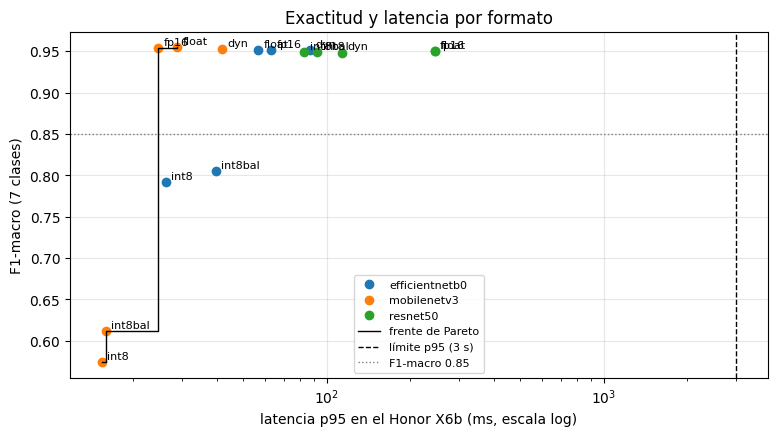

,run,formato,F1-macro,p50 ms,p95 ms,memoria MB,viable,incumple
11,A_mobilenetv3,model_int8,0.574,12.936,15.388,24.750,False,"f1_macro, recall_macro, reject_recall, false_a..."
14,A_mobilenetv3,model_int8bal,0.612,12.794,15.879,24.859,False,"f1_macro, recall_macro, reject_recall, false_a..."
12,A_mobilenetv3,model_fp16,0.954,18.782,24.545,38.383,False,reject_recall
10,A_mobilenetv3,model,0.955,18.998,28.868,43.262,False,reject_recall


In [16]:
# Frente de Pareto de F1-macro frente a latencia p95 en el Honor X6b (sección 5.7), sobre todas las configuraciones
# medidas, viables o no: las que ninguna otra supera a la vez en F1-macro y en rapidez. Sin el control sin máscara,
# que no va al teléfono (la superposición delata el local).
if DISPOSITIVO:
    t = tabla[~tabla.run.str.endswith('nomask')].dropna(subset=['p95 ms']).sort_values(['p95 ms', 'F1-macro'], ascending=[True, False])
    frente = t[t['F1-macro'] > t['F1-macro'].cummax().shift(fill_value=-1)]
    fig, a = plt.subplots(figsize=(9, 4.5))
    for n, d in t.groupby('run'):
        a.plot(d['p95 ms'], d['F1-macro'], 'o', label=n[2:])
        for _, r in d.iterrows():
            a.annotate(r.formato.replace('model_', '').replace('model', 'float'), (r['p95 ms'], r['F1-macro']),
                       xytext=(4, 2), textcoords='offset points', fontsize=8)
    a.step(frente['p95 ms'], frente['F1-macro'], 'k-', where='post', lw=1, label='frente de Pareto')
    a.axvline(THRESHOLDS['lat_p95_ms'], color='k', ls='--', lw=1, label='límite p95 (3 s)')
    a.axhline(THRESHOLDS['f1_macro'], color='gray', ls=':', lw=1, label='F1-macro 0.85')
    a.set_xscale('log'); a.set_xlabel('latencia p95 en el Honor X6b (ms, escala log)'); a.set_ylabel('F1-macro (7 clases)')
    a.grid(alpha=.3); a.legend(fontsize=8); plt.title('Exactitud y latencia por formato'); plt.show()
    display(frente[['run', 'formato', 'F1-macro', 'p50 ms', 'p95 ms', 'memoria MB', 'viable', 'incumple']].round(3))
else:
    print('Sin dispositivo.csv en RUNS_DIR: el frente de Pareto espera la medición en el Honor X6b (python -m tesis.device).')


In [17]:
# Verificación por par de clases (sección 5.9) del candidato al teléfono: el formato de ≤ 20 MB con mayor F1-macro.
# Fila: lo que muestra la foto; columna: lo declarado. Diagonal: falsas alarmas sobre los pares correctos; fuera de ella,
# detección de la discrepancia.
cand = tabla[(tabla.MB <= THRESHOLDS['size_mb']) & ~tabla.run.str.endswith('nomask')].sort_values('F1-macro').iloc[-1]
print(f'Candidato: {cand.run} {cand.formato}')
test, P = cargar(cand.run, cand.formato)
y, st = test.label.map(IDX).values, test.store.values
hist = (test.source == 'hist').values
img, dec, _ = verification_pairs(y[hist], st[hist], CONTRATOS)
pares = pd.DataFrame({'foto': np.array(CLASSES)[y[hist][img]], 'declarado': np.array(CLASSES)[dec],
                      'alerta': conditional_pred(P[hist], st[hist], CONTRATOS)[img] != dec})
display(pares.pivot_table('alerta', 'foto', 'declarado', aggfunc='mean').round(3))
print('Pares por celda:')
display(pares.pivot_table('alerta', 'foto', 'declarado', aggfunc='size').fillna(0).astype(int))
# Errores reales de campo en ODK: qué se declaró, qué muestra la foto y cuántos detecta el candidato.
odk = ((test.source == 'odk') & test.declarado.isin(MUEBLES)).values
campo = test[odk].assign(alerta=conditional_pred(P[odk], st[odk], CONTRATOS) != test.declarado[odk].map(IDX).values)
campo[campo.label != campo.declarado].groupby(['declarado', 'label']).alerta.agg(errores='size', detectados='sum')

Candidato: A_mobilenetv3 model


declarado,cabecera,check_out,chiclera,exhibidor_piso,lateral
foto,,,,,
cabecera,0.025,0.999,1.000,0.981,0.995
check_out,0.999,0.010,0.993,0.996,0.999
chiclera,1.000,0.983,0.018,0.999,1.000
exhibidor_piso,0.972,0.988,1.000,0.057,0.978
lateral,0.976,1.000,1.000,0.952,0.071


Pares por celda:


declarado,cabecera,check_out,chiclera,exhibidor_piso,lateral
foto,,,,,
cabecera,1125,992,432,1108,915
check_out,5953,6525,2926,6398,6080
chiclera,952,1236,1244,1170,1054
exhibidor_piso,1171,1035,540,1228,978
lateral,493,455,367,496,524


errores  detectados
declarado      label                                
cabecera       contenido_ajeno         6           6
               exhibidor_piso         13          13
               lateral                12          12
check_out      captura_invalida        1           0
               chiclera                5           5
chiclera       check_out              13          13
exhibidor_piso cabecera               18          15
               contenido_ajeno         1           0
               lateral                17          11
lateral        cabecera                5           5
               contenido_ajeno         4           4

In [18]:
# Hipótesis 5.8: ¿ResNet-50 supera de forma significativa a la mejor arquitectura eficiente? IC 95 % de la diferencia
# de F1-macro (7 clases) por bootstrap pareado que remuestrea locales. Significativa si el IC excluye el cero.
f1a = tabla[tabla.formato == 'model'].set_index('run')['F1-macro']
mejor = f1a[['A_efficientnetb0', 'A_mobilenetv3']].idxmax()
test, P = cargar('A_resnet50')
y, pr = test.label.map(IDX).values, P.argmax(1)
f1 = lambda p: f1_score(y, p, labels=TODAS, average='macro', zero_division=0)
for run, fmt in dict.fromkeys([(mejor, 'model'), (cand.run, cand.formato)]):  # mejor eficiente y candidato
    pe = cargar(run, fmt)[1].argmax(1)
    lo, hi = bootstrap_f1_diff(y, pr, pe, test.store.values)
    print(f'ResNet-50 float32 − {run[2:]} {fmt}: {f1(pr) - f1(pe):+.3f}, IC 95 % [{lo:+.3f}, {hi:+.3f}] → '
          + ('diferencia significativa' if lo > 0 or hi < 0 else 'sin diferencia significativa'))
mb = tabla[tabla.run == 'A_resnet50'].MB.min()
print(f'ResNet-50 pesa {mb:.0f} MB en su formato más chico (límite {THRESHOLDS["size_mb"]} MB).')

ResNet-50 float32 − mobilenetv3 model: -0.005, IC 95 % [-0.015, +0.015] → sin diferencia significativa
ResNet-50 pesa 23 MB en su formato más chico (límite 20 MB).


In [19]:
# Objetivo 6: errores del candidato por clase (precision, recall y matriz de confusión normalizada por fila, lo que
# muestra la foto) y por cadena y fuente, con la exactitud de las tres arquitecturas en float32 como referencia.
test, P = cargar(cand.run, cand.formato)
y = test.label.map(IDX).values
pred = np.array(CLASSES)[P.argmax(1)]
display(pd.DataFrame(report(y, P)['per_class']).T.round(3))
display(pd.crosstab(test.label, pred, rownames=['foto'], colnames=['predicción'], normalize='index').round(3))

aciertos = {}
for run, fmt in [(r, 'model') for r in RUNS_A[:3]] + [(cand.run, cand.formato)]:
    t, Pr = cargar(run, fmt)
    assert (t.path == test.path).all()
    aciertos[f'exactitud {run[2:]} {fmt}'] = Pr.argmax(1) == y
g = test.assign(cadena=test.store.str.split().str[0], pred=pred, **aciertos)
g['error'] = np.where(g.pred != g.label, g.label + ' → ' + g.pred, None)

def resumen(d):
    pres = d.label.value_counts()[lambda s: s >= 10].index
    errores = d.error.value_counts()
    return pd.Series({'fotos': len(d), 'locales': d.store.nunique(), **d[list(aciertos)].mean(),
                      'F1-macro candidato (clases ≥10 fotos)': f1_score(d.label, d.pred, labels=pres, average='macro', zero_division=0),
                      'error más frecuente': f'{errores.index[0]} ({errores.iloc[0]})' if len(errores) else ''})

g.groupby(['cadena', 'source']).apply(resumen, include_groups=False).infer_objects().round(3)

,precision,recall,support
chiclera,0.986,0.984,1531.0
lateral,0.941,0.927,616.0
check_out,0.993,0.990,6904.0
cabecera,0.957,0.967,1316.0
exhibidor_piso,0.927,0.945,1427.0
captura_invalida,0.941,0.889,18.0
contenido_ajeno,0.961,0.959,436.0


predicción,cabecera,captura_invalida,check_out,chiclera,contenido_ajeno,exhibidor_piso,lateral
foto,,,,,,,
cabecera,0.967,0.000,0.002,0.000,0.002,0.025,0.004
captura_invalida,0.000,0.889,0.056,0.000,0.056,0.000,0.000
check_out,0.001,0.000,0.990,0.003,0.001,0.004,0.001
chiclera,0.000,0.001,0.015,0.984,0.000,0.001,0.000
contenido_ajeno,0.000,0.000,0.011,0.000,0.959,0.028,0.002
exhibidor_piso,0.026,0.000,0.011,0.000,0.002,0.945,0.017
lateral,0.019,0.000,0.000,0.002,0.002,0.050,0.927


fotos  locales  exactitud resnet50 model  \
cadena     source                                             
CORAL      hist     2467        3                     0.989   
           odk        95        3                     0.905   
FAVORITA   hist      523       32                     0.887   
           odk       107       11                     0.963   
LIRIS      odk         2        1                     1.000   
ROSADO     hist     1175       10                     0.956   
           odk        27        6                     0.926   
SANTAMARIA hist     1364        7                     0.981   
           odk       188        6                     0.888   
TIA        hist     5541       52                     0.979   
           odk       759       31                     0.995   

                   exactitud efficientnetb0 model  \
cadena     source                                   
CORAL      hist                             0.986   
           odk                              0.916   
FAVORITA   hist                             0.958   
           odk                              0.963   
LIRIS      odk                              1.000   
ROSADO     hist                             0.969   
           odk                              0.963   
SANTAMARIA hist                             0.988   
           odk                              0.872   
TIA        hist                             0.977   
           odk                              0.989   

                   exactitud mobilenetv3 model  \
cadena     source                                
CORAL      hist                          0.991   
           odk                           0.905   
FAVORITA   hist                          0.933   
           odk                           0.953   
LIRIS      odk                           1.000   
ROSADO     hist                          0.962   
           odk                           1.000   
SANTAMARIA hist                          0.988   
           odk                           0.878   
TIA        hist                          0.977   
           odk                           0.993   

                   F1-macro candidato (clases ≥10 fotos)  \
cadena     source                                          
CORAL      hist                                    0.941   
           odk                                     0.835   
FAVORITA   hist                                    0.884   
           odk                                     0.944   
LIRIS      odk                                       NaN   
ROSADO     hist                                    0.923   
           odk                                     1.000   
SANTAMARIA hist                                    0.970   
           odk                                     0.833   
TIA        hist                                    0.969   
           odk                                     0.995   

                                    error más frecuente  
cadena     source                                        
CORAL      hist           exhibidor_piso → cabecera (4)  
           odk             lateral → exhibidor_piso (5)  
FAVORITA   hist           exhibidor_piso → cabecera (8)  
           odk     contenido_ajeno → exhibidor_piso (4)  
LIRIS      odk                                           
ROSADO     hist          exhibidor_piso → cabecera (16)  
           odk                                           
SANTAMARIA hist         contenido_ajeno → check_out (3)  
           odk            cabecera → exhibidor_piso (9)  
TIA        hist         check_out → exhibidor_piso (22)  
           odk                 chiclera → check_out (2)